In [28]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras import layers

In [29]:
path = "fashion mnist"

train = keras.utils.image_dataset_from_directory(
    path,
    color_mode="rgb",
    batch_size=32,
    image_size=(224,224),
    seed=123,
    subset="training",
    validation_split=0.2
)
test = keras.utils.image_dataset_from_directory(
    path,
    color_mode="rgb",
    batch_size=32,
    image_size=(224,224),
    seed=123,
    subset="validation",
    validation_split=0.2
)
classes = train.class_names
print(classes)

Found 145 files belonging to 11 classes.
Using 116 files for training.
Found 145 files belonging to 11 classes.
Using 29 files for validation.
['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser', 'train']


In [30]:
base = keras.applications.VGG16(
    weights = None,
    include_top=False,
    input_shape=(224,224,3)
)

base.load_weights("vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5")

base.trainable = False

In [31]:
model = keras.Sequential([
    layers.Input(shape=(224,224,3)),
    layers.Lambda(keras.applications.vgg16.preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(classes), activation="softmax")
])

In [32]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train,
    validation_data=test,
    epochs=2
)

Epoch 1/2
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.1207 - loss: 3.9747 - val_accuracy: 0.2759 - val_loss: 2.8828
Epoch 2/2
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.3707 - loss: 2.5831 - val_accuracy: 0.4138 - val_loss: 2.2380


In [33]:
loss, accuracy = model.evaluate(test)

print("Loss:", loss)
print("Accuracy:", accuracy*100)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.4138 - loss: 2.2380
Loss: 2.2379653453826904
Accuracy: 41.37931168079376


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


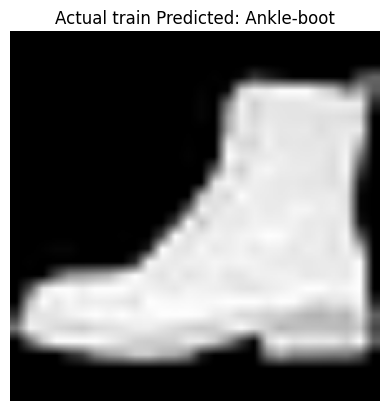

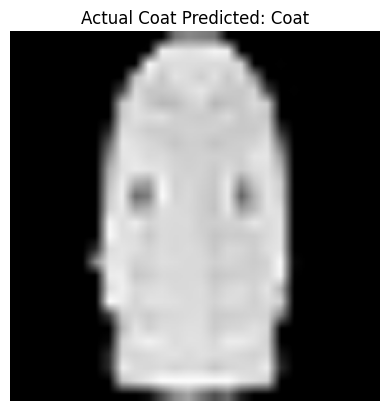

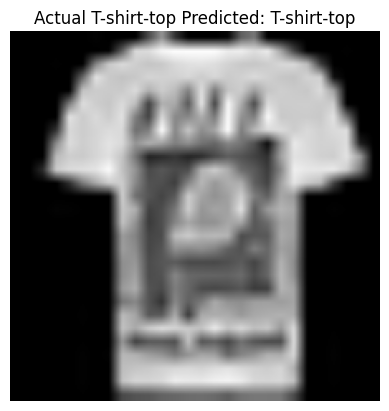

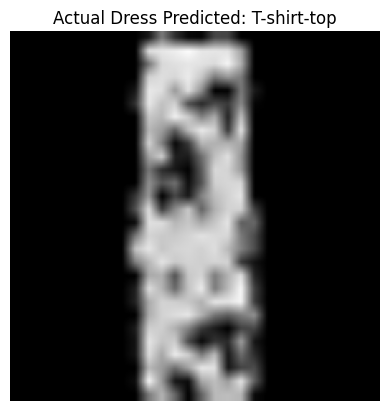

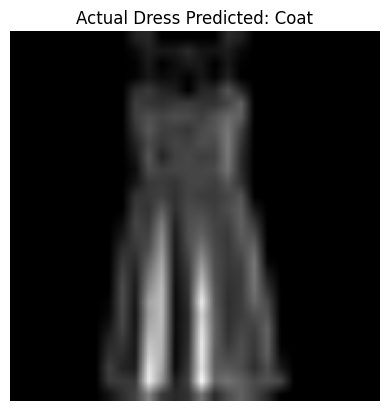

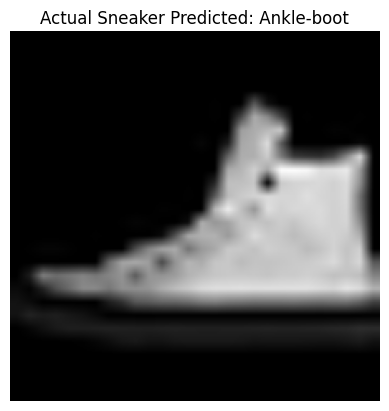

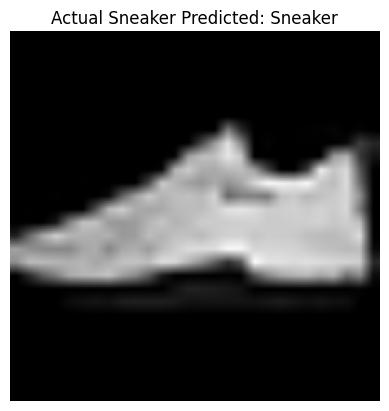

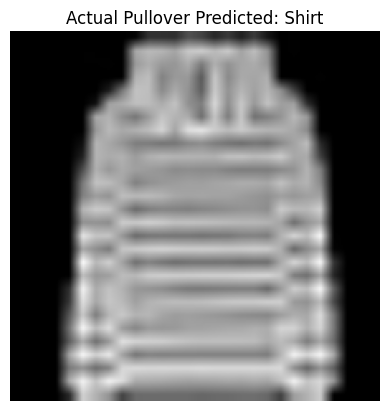

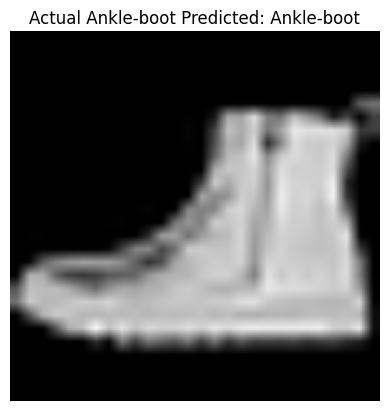

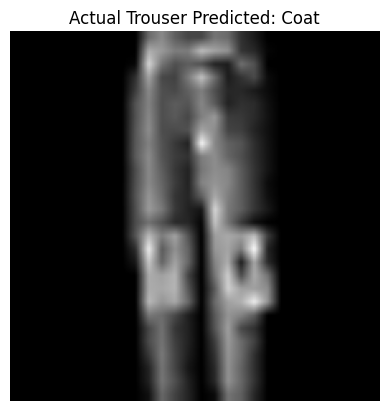

In [34]:
images, labels = next(iter(test))


predictions = model.predict(images)

for i in range(10):
    plt.imshow(images[i].numpy().astype("uint8"))

    plt.title(f"Actual {classes[labels[i]]} Predicted: {classes[np.argmax(predictions[i])]}")

    plt.axis("off")

    plt.show()

In [36]:
base.trainable=True

for layer in base.layers[:-4]:
    layer.trainable=False

model.compile(
    optimizer = keras.optimizers.Adam(0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)    

In [37]:
model.fit(train,validation_data=test,
         epochs=2)

Epoch 1/2
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.5345 - loss: 1.6902 - val_accuracy: 0.5172 - val_loss: 1.7894
Epoch 2/2
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.6810 - loss: 1.1101 - val_accuracy: 0.5517 - val_loss: 1.5560


In [38]:
loss, accuracy = model.evaluate(test)

print("Loss:", loss)
print("Accuracy:", accuracy*100)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5517 - loss: 1.5560
Loss: 1.5560418367385864
Accuracy: 55.17241358757019
